# Circular Separability

CSI4106 Introduction to Artificial Intelligence

Marcel Turcotte (School of Electrical Engineering and Computer Science,
University of Ottawa)  
2026-10-13

This self-study notebook extends Lecture 11’s discussion of nonlinear
decision boundaries. We compare two ways to obtain a useful
representation: designing features for logistic regression and learning
hidden representations with a neural network. It complements the circle
dataset in <a href="https://playground.tensorflow.org" class="external"
data-icon="true">TensorFlow Playground</a>.

The Keras examples can be explored now; the training methods, losses,
and regularization techniques are developed in Lectures 12–14.

## Data

The inner circle is class 1, and the outer ring is class 0. No straight
line can separate these two classes in the original input plane.

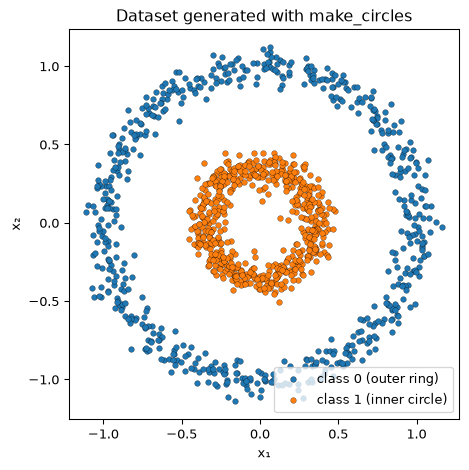

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures

X_circles, y_circles = make_circles(
    n_samples=1200, factor=0.35, noise=0.06, random_state=42
)


def plot_samples(ax, X, y, labels=("class 0", "class 1")):
    for label in (0, 1):
        ax.scatter(
            X[y == label, 0], X[y == label, 1],
            color=f"C{label}", label=labels[label], s=18,
            edgecolor="k", linewidth=0.2,
        )
    ax.set_xlabel("x₁")
    ax.set_ylabel("x₂")
    ax.set_aspect("equal")
    ax.legend()


fig, ax = plt.subplots(figsize=(5, 5))
plot_samples(ax, X_circles, y_circles,
             labels=("class 0 (outer ring)", "class 1 (inner circle)"))
ax.set_title("Dataset generated with make_circles")
plt.tight_layout()
plt.show()

## Feature engineering

Logistic regression using only $x_1$ and $x_2$ has a straight decision
boundary, so it cannot separate the inner circle from the surrounding
ring. Logistic regression can nevertheless produce a nonlinear boundary
in the input plane if we give it nonlinear features.

TensorFlow Playground offers $x_1^2$ and $x_2^2$ as additional features.
A network with no hidden layers and one sigmoid output is logistic
regression on the selected features. Keeping the two original inputs and
both squared inputs gives four features; selecting only the squared
inputs gives two.

For a simpler visualization, combine the squared inputs into one
feature:

$$
r = x_1^2 + x_2^2.
$$

Here, $r$ denotes the **squared distance from the origin**, rather than
the radius itself. Inner-circle points have small $r$; outer-ring points
have large $r$. Squaring the distance preserves their ordering, so
computing a square root is unnecessary.

For the sample generated above, the two bands are separated in
$r$-space. A threshold $r^*$ can separate the classes:

$$
\text{inner if } r < r^*, \qquad \text{outer if } r > r^*.
$$

The same threshold corresponds to a circle in the original input plane.
With more noise, the radial bands may overlap, and perfect separation
may no longer be possible.

## Fit a model in r-space

All models for a dataset use the same split: 60% training, 20%
validation, and 20% test. Only training examples are used to fit the
parameters. The neural network uses validation loss for early stopping;
the test examples are reserved for the final comparison.

In [2]:
def split_dataset(X, y):
    X_train, X_holdout, y_train, y_holdout = train_test_split(
        X, y, test_size=0.4, random_state=42, stratify=y
    )
    X_valid, X_test, y_valid, y_test = train_test_split(
        X_holdout, y_holdout, test_size=0.5,
        random_state=42, stratify=y_holdout,
    )
    return X_train, X_valid, X_test, y_train, y_valid, y_test


def radial_features(X):
    return (X[:, 0]**2 + X[:, 1]**2).reshape(-1, 1)


X_train, X_valid, X_test, y_train, y_valid, y_test = split_dataset(
    X_circles, y_circles
)
r_circles = radial_features(X_circles)

clf_raw = LogisticRegression().fit(X_train, y_train)
clf_r = LogisticRegression().fit(radial_features(X_train), y_train)

w = clf_r.coef_[0, 0]
b = clf_r.intercept_[0]
r_threshold = -b / w
print(f"Decision threshold: r* = {r_threshold:.3f}")

Decision threshold: r* = 0.546

The radial model estimates $p(y=1\mid r)=\sigma(wr+b)$. Its decision
boundary is where $wr+b=0$, or $r^*=-b/w$. The learned weight is
negative because class 1 occupies the smaller radii.

## 3D view

Lifting each point to $(x_1,x_2,r)$ makes the decision boundary a
horizontal plane. Rotate the interactive view to see how the plane
separates the two bands.

In [3]:
import plotly.graph_objects as go

gx = np.linspace(X_circles[:, 0].min() - 0.2,
                 X_circles[:, 0].max() + 0.2, 30)
gy = np.linspace(X_circles[:, 1].min() - 0.2,
                 X_circles[:, 1].max() + 0.2, 30)
GX, GY = np.meshgrid(gx, gy)
GZ = np.full_like(GX, r_threshold)

plane = go.Surface(
    x=GX, y=GY, z=GZ, opacity=0.35, showscale=False,
    colorscale=[[0, "gray"], [1, "gray"]], hoverinfo="skip",
    name="decision plane",
)
scatters = [
    go.Scatter3d(
        x=X_circles[y_circles == label, 0],
        y=X_circles[y_circles == label, 1],
        z=r_circles[y_circles == label, 0], mode="markers",
        marker=dict(size=3, color=color), name=name,
        hovertemplate="x₁=%{x:.3f}<br>x₂=%{y:.3f}<br>r=%{z:.3f}<extra></extra>",
    )
    for label, color, name in (
        (0, "#1f77b4", "class 0 (outer ring)"),
        (1, "#ff7f0e", "class 1 (inner circle)"),
    )
]
fig = go.Figure(data=[plane, *scatters])
fig.update_scenes(
    xaxis_title="x₁", yaxis_title="x₂", zaxis_title="r = x₁² + x₂²",
    aspectmode="cube", camera=dict(eye=dict(x=1.6, y=1.6, z=0.9)),
)
fig.update_layout(
    margin=dict(l=0, r=0, b=0, t=40),
    title=f"Decision plane at r* ≈ {r_threshold:.3f}",
)
fig.show()

The static view below shows the same relationship for readers whose
notebook viewer or PDF export does not display interactive figures.

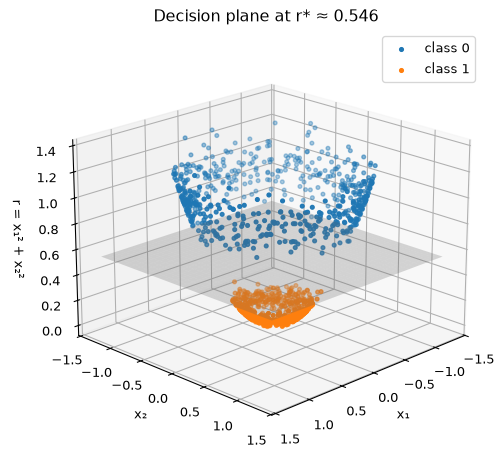

In [4]:
fig = plt.figure(figsize=(7, 5))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(GX, GY, GZ, color="gray", alpha=0.25)
for label in (0, 1):
    ax.scatter(
        X_circles[y_circles == label, 0],
        X_circles[y_circles == label, 1],
        r_circles[y_circles == label, 0],
        color=f"C{label}", s=8, label=f"class {label}",
    )
ax.set_xlabel("x₁")
ax.set_ylabel("x₂")
ax.set_zlabel("r = x₁² + x₂²")
ax.set_title(f"Decision plane at r* ≈ {r_threshold:.3f}")
ax.view_init(elev=20, azim=45)
ax.legend()
plt.tight_layout()
plt.show()

## Linear separability in 1D (r-space)

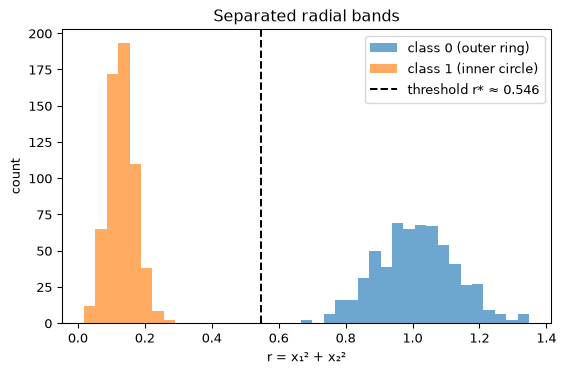

In [5]:
plt.figure(figsize=(6, 4))
bins = np.linspace(r_circles.min(), r_circles.max(), 40)
plt.hist(r_circles[y_circles == 0, 0], bins=bins, alpha=0.65,
         label="class 0 (outer ring)")
plt.hist(r_circles[y_circles == 1, 0], bins=bins, alpha=0.65,
         label="class 1 (inner circle)")
plt.axvline(r_threshold, linestyle="--", color="k",
            label=f"threshold r* ≈ {r_threshold:.3f}")
plt.xlabel("r = x₁² + x₂²")
plt.ylabel("count")
plt.title("Separated radial bands")
plt.legend()
plt.tight_layout()
plt.show()

## Logistic model in 1D r-space

The probability of class 1 decreases as the distance from the origin
increases. The dashed line marks the probability threshold of 0.5.

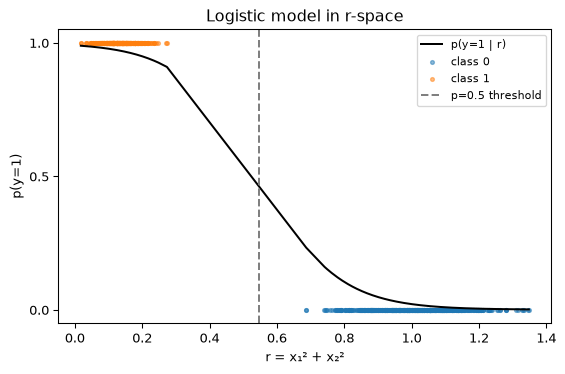

In [6]:
r_sorted = np.sort(r_circles[:, 0])
p_sorted = clf_r.predict_proba(r_sorted.reshape(-1, 1))[:, 1]

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(r_sorted, p_sorted, color="k", label="p(y=1 | r)")
for label in (0, 1):
    positions = r_circles[y_circles == label, 0]
    ax.scatter(positions, np.full_like(positions, label),
               s=8, alpha=0.5, color=f"C{label}", label=f"class {label}")
ax.axvline(r_threshold, linestyle="--", color="gray", label="p=0.5 threshold")
ax.set_yticks([0, 0.5, 1])
ax.set_ylim(-0.05, 1.05)
ax.set_xlabel("r = x₁² + x₂²")
ax.set_ylabel("p(y=1)")
ax.set_title("Logistic model in r-space")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## Decision boundary from radial features

The plotting helpers below will also be used for the quadratic model and
the neural networks. Shading shows the estimated probability of class 1;
the black contour marks $p=0.5$. The points show the full generated
dataset, while model fitting uses only the training split.

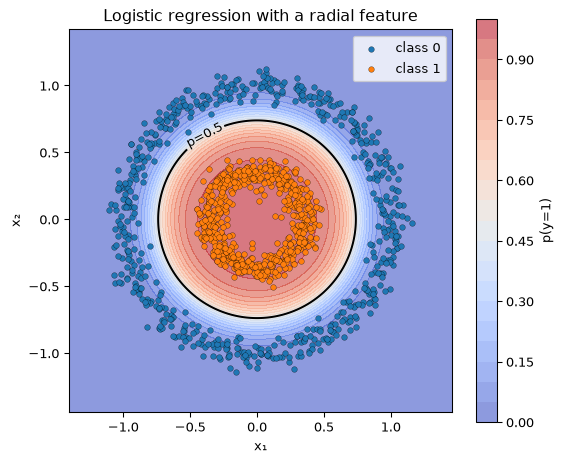

In [7]:
def make_grid(X):
    xx, yy = np.meshgrid(
        np.linspace(X[:, 0].min() - 0.3, X[:, 0].max() + 0.3, 300),
        np.linspace(X[:, 1].min() - 0.3, X[:, 1].max() + 0.3, 300),
    )
    return xx, yy, np.column_stack((xx.ravel(), yy.ravel()))


def plot_decision_boundary(xx, yy, probabilities, X, y, title):
    probabilities = probabilities.reshape(xx.shape)
    fig, ax = plt.subplots(figsize=(6, 5))
    shading = ax.contourf(xx, yy, probabilities,
                          levels=np.linspace(0, 1, 21), cmap="coolwarm", alpha=0.6)
    boundary = ax.contour(xx, yy, probabilities, levels=[0.5], colors="k")
    ax.clabel(boundary, fmt={0.5: "p=0.5"})
    plot_samples(ax, X, y)
    ax.set_title(title)
    fig.colorbar(shading, ax=ax, label="p(y=1)")
    plt.tight_layout()
    plt.show()


xx, yy, grid = make_grid(X_circles)
p_r = clf_r.predict_proba(radial_features(grid))[:, 1]
plot_decision_boundary(xx, yy, p_r, X_circles, y_circles,
                       "Logistic regression with a radial feature")

## Decision boundary from quadratic features

<a
href="https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PolynomialFeatures.html"
class="external" data-icon="true"><code>PolynomialFeatures</code></a>
with degree 2 and no constant column produces five features:

$$
x_1,\quad x_2,\quad x_1^2,\quad x_1x_2,\quad x_2^2.
$$

The radial model constrains the squared inputs to share one coefficient,
because $wr=w(x_1^2+x_2^2)$. The quadratic model can weight all five
features independently. Both can separate these circles, but their
fitted boundaries and probabilities need not be identical. Their default
regularization also acts on different parameterizations.

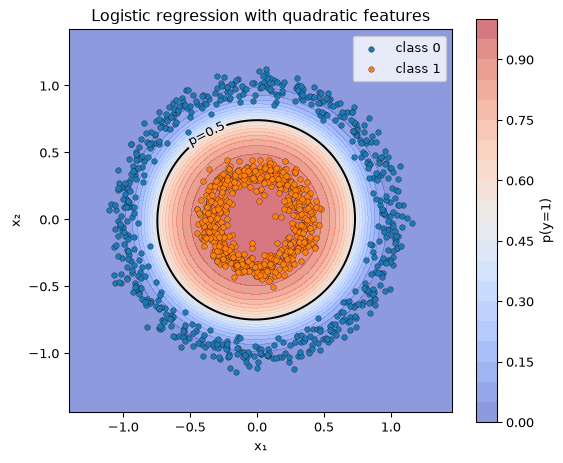

In [8]:
quad = Pipeline([
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("logreg", LogisticRegression()),
]).fit(X_train, y_train)

p_quad = quad.predict_proba(grid)[:, 1]
plot_decision_boundary(xx, yy, p_quad, X_circles, y_circles,
                       "Logistic regression with quadratic features")

## Neural network

The neural network receives only the original inputs $x_1$ and $x_2$. It
has **two hidden layers**, each with four units, followed by one sigmoid
output: three layers with trainable parameters. The hidden layers use
`tanh`, a nonlinear activation, and learn a representation from the
training examples.

This is one working configuration, rather than a claim that `tanh`
always trains faster or better than other activations. Training success
depends on the data, initialization, architecture, and optimization
settings.

In [9]:
from tensorflow import keras


def make_mlp():
    keras.utils.set_random_seed(42)
    model = keras.Sequential([
        keras.layers.Input(shape=(2,)),
        keras.layers.Dense(4, activation="tanh"),
        keras.layers.Dense(4, activation="tanh"),
        keras.layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.01),
        loss="binary_crossentropy", metrics=["accuracy"],
    )
    return model


circle_mlp = make_mlp()

Early stopping monitors validation loss and restores the weights from
the epoch with the lowest validation loss. This epoch need not have the
highest validation accuracy. We therefore evaluate the restored model
directly, rather than taking unrelated values from the training history.
See the <a href="https://keras.io/api/callbacks/early_stopping/"
class="external" data-icon="true">Keras documentation</a> for the
callback’s parameters.

Epochs run: 300
Restored model: training accuracy = 1.000; validation accuracy = 1.000

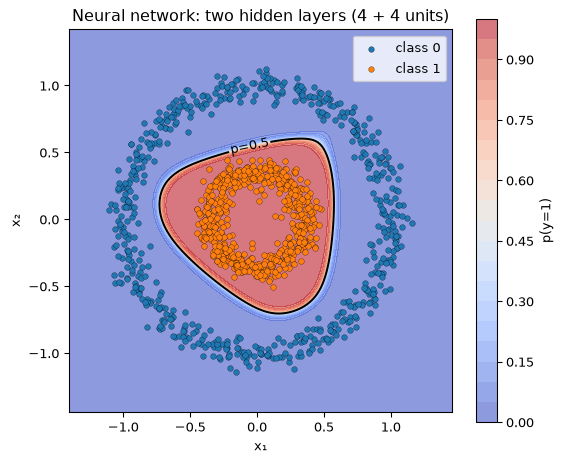

In [10]:
circle_history = circle_mlp.fit(
    X_train, y_train, validation_data=(X_valid, y_valid),
    epochs=300, batch_size=64, verbose=0,
    callbacks=[keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=20, restore_best_weights=True,
    )],
)
_, train_accuracy = circle_mlp.evaluate(X_train, y_train, verbose=0)
_, valid_accuracy = circle_mlp.evaluate(X_valid, y_valid, verbose=0)
print(f"Epochs run: {len(circle_history.history['loss'])}")
print(f"Restored model: training accuracy = {train_accuracy:.3f}; "
      f"validation accuracy = {valid_accuracy:.3f}")

p_mlp = circle_mlp.predict(grid, verbose=0).ravel()
plot_decision_boundary(xx, yy, p_mlp, X_circles, y_circles,
                       "Neural network: two hidden layers (4 + 4 units)")

### Final evaluation on the circle test set

The comparison uses the same held-out examples for every model. It
illustrates the effect of representation on this dataset; a successful
run does not guarantee the same results for other datasets or training
settings.

In [11]:
_, circle_test_accuracy = circle_mlp.evaluate(X_test, y_test, verbose=0)
circle_scores = {
    "Logistic: original inputs": clf_raw.score(X_test, y_test),
    "Logistic: radial feature": clf_r.score(radial_features(X_test), y_test),
    "Logistic: quadratic features": quad.score(X_test, y_test),
    "Neural network: original inputs": circle_test_accuracy,
}
for name, accuracy in circle_scores.items():
    print(f"{name:<34} test accuracy = {accuracy:.3f}")

Logistic: original inputs          test accuracy = 0.471
Logistic: radial feature           test accuracy = 1.000
Logistic: quadratic features       test accuracy = 1.000
Neural network: original inputs    test accuracy = 1.000

## XOR dataset

In Lecture 11, a hidden layer was configured by hand to compute Boolean
XOR. Here, a continuous version lets us explore learning a nonlinear
boundary. Interpret $A$ as $(x_1>0)$ and $B$ as $(x_2>0)$. Class 1
corresponds to $A\oplus B$: exactly one input is positive, giving the
upper-left and lower-right quadrants.

A straight decision boundary cannot separate the classes in the original
plane. Both suitable engineered features and a neural network can
address this limitation.

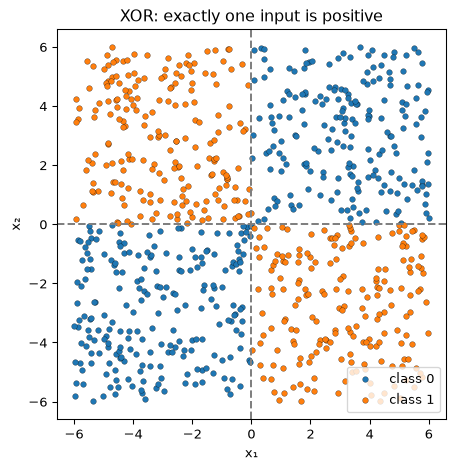

In [12]:
rng = np.random.default_rng(42)
X_xor = rng.uniform(-6, 6, size=(800, 2))
A = X_xor[:, 0] > 0
B = X_xor[:, 1] > 0
y_xor = np.logical_xor(A, B).astype(int)

fig, ax = plt.subplots(figsize=(5, 5))
plot_samples(ax, X_xor, y_xor)
ax.axhline(0, color="gray", linestyle="--")
ax.axvline(0, color="gray", linestyle="--")
ax.set_title("XOR: exactly one input is positive")
plt.tight_layout()
plt.show()

### Does the radial feature still work?

The radial feature discards sign information. Points at the same
distance from the origin can belong to either class, so the feature that
separated the circles cannot separate XOR. In this sampling
distribution, the label is independent of the squared radius; a finite
sample may nevertheless show small accidental associations.

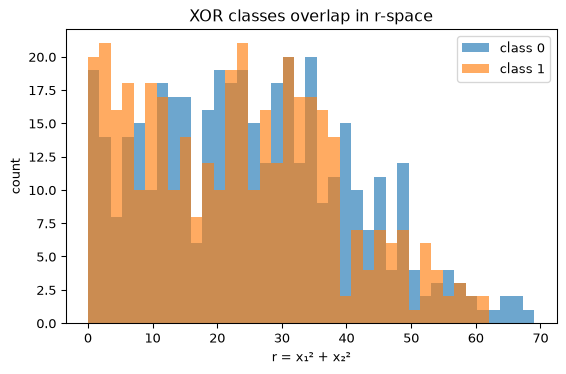

In [13]:
r_xor = radial_features(X_xor)
plt.figure(figsize=(6, 4))
bins = np.linspace(r_xor.min(), r_xor.max(), 40)
for label in (0, 1):
    plt.hist(r_xor[y_xor == label, 0], bins=bins, alpha=0.65,
             label=f"class {label}")
plt.xlabel("r = x₁² + x₂²")
plt.ylabel("count")
plt.title("XOR classes overlap in r-space")
plt.legend()
plt.tight_layout()
plt.show()

### A feature that preserves the relevant information

The product $s=x_1x_2$ distinguishes opposite signs from equal signs.
Away from the coordinate axes, class 1 has $s<0$, while class 0 has
$s>0$. A threshold at zero separates the classes in this feature space.

The quadratic feature expansion already includes $x_1x_2$. Thus, the
full quadratic model can also represent an XOR boundary, even though the
radial feature alone cannot.

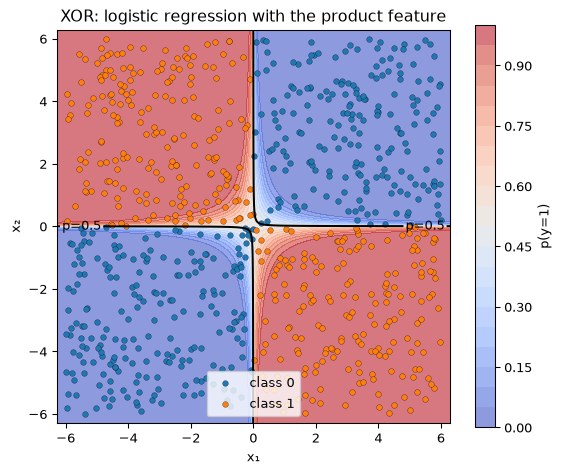

In [14]:
def product_features(X):
    return (X[:, 0] * X[:, 1]).reshape(-1, 1)


X_train, X_valid, X_test, y_train, y_valid, y_test = split_dataset(X_xor, y_xor)
xor_raw = LogisticRegression().fit(X_train, y_train)
xor_radial = LogisticRegression().fit(radial_features(X_train), y_train)
xor_product = LogisticRegression().fit(product_features(X_train), y_train)
xor_quad = Pipeline([
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("logreg", LogisticRegression()),
]).fit(X_train, y_train)

xx, yy, grid = make_grid(X_xor)
p_product = xor_product.predict_proba(product_features(grid))[:, 1]
plot_decision_boundary(xx, yy, p_product, X_xor, y_xor,
                       "XOR: logistic regression with the product feature")

### Learning from the original inputs

We train a fresh neural network with the same architecture and settings
used for the circles. Only the original inputs are provided; we do not
supply the radial or product features. The plotting helper and
model-building function are reused.

Epochs run: 126
Restored model: training accuracy = 1.000; validation accuracy = 0.994

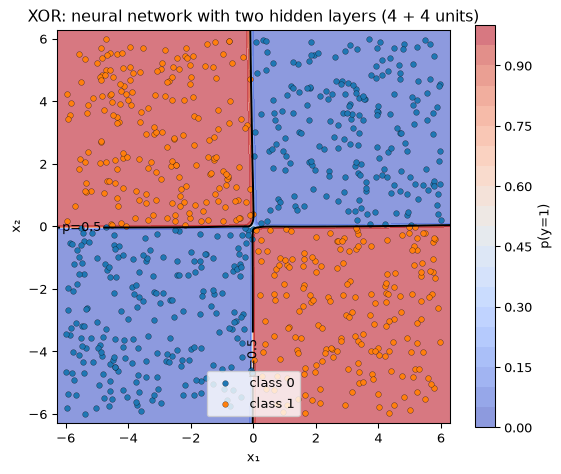

In [15]:
xor_mlp = make_mlp()
xor_history = xor_mlp.fit(
    X_train, y_train, validation_data=(X_valid, y_valid),
    epochs=300, batch_size=64, verbose=0,
    callbacks=[keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=20, restore_best_weights=True,
    )],
)
_, train_accuracy = xor_mlp.evaluate(X_train, y_train, verbose=0)
_, valid_accuracy = xor_mlp.evaluate(X_valid, y_valid, verbose=0)
print(f"Epochs run: {len(xor_history.history['loss'])}")
print(f"Restored model: training accuracy = {train_accuracy:.3f}; "
      f"validation accuracy = {valid_accuracy:.3f}")

p_mlp = xor_mlp.predict(grid, verbose=0).ravel()
plot_decision_boundary(xx, yy, p_mlp, X_xor, y_xor,
                       "XOR: neural network with two hidden layers (4 + 4 units)")

### Final evaluation on the XOR test set

In [16]:
_, xor_test_accuracy = xor_mlp.evaluate(X_test, y_test, verbose=0)
xor_scores = {
    "Logistic: original inputs": xor_raw.score(X_test, y_test),
    "Logistic: radial feature": xor_radial.score(radial_features(X_test), y_test),
    "Logistic: product feature": xor_product.score(product_features(X_test), y_test),
    "Logistic: quadratic features": xor_quad.score(X_test, y_test),
    "Neural network: original inputs": xor_test_accuracy,
}
for name, accuracy in xor_scores.items():
    print(f"{name:<34} test accuracy = {accuracy:.3f}")

Logistic: original inputs          test accuracy = 0.512
Logistic: radial feature           test accuracy = 0.556
Logistic: product feature          test accuracy = 1.000
Logistic: quadratic features       test accuracy = 0.988
Neural network: original inputs    test accuracy = 1.000

## Takeaways

- Linear separability depends on the representation. A linear classifier
  on nonlinear features can have a nonlinear boundary in the original
  input space.
- Useful features depend on the task: squared radius separates these
  circles, while the product distinguishes the XOR quadrants.
- Hidden layers provide another way to learn a representation. They do
  not guarantee that training will find suitable parameters or that a
  neural network will outperform a model with well-chosen features.
- These experiments illustrate Lecture 11’s distinction between what an
  architecture can represent and what a training process finds from
  data.